# Funding Carry 02, Stage A — can funding be predicted, by how much, and does the volatility engine help?

Pre-registration: `discussions/Funding_Carry/003_claude_fc02_stage_a_preregistration.md`. Code: `src/data_engineering/modeling/funding_predict.py`.

- **Target:** next-7-day annualized funding $y_7$ (primary); $y_1$, $y_{30}$ secondary. One row per asset and day at 00:05 UTC.
- **Blocks, added in order (asset fixed effects in every model):** persistence P → premium PR → momentum M → open interest and positioning OI → breadth B → naive volatility V → **engine E** (AM-T-HAR-Blend level, VD18 HAR_4 refitted on Binance spot, TRAIN bars only).
- **Split:** TRAIN origins before 2025-10-01 (target window inside TRAIN), TEST from 2025-10-01. Out-of-sample $R^2$ is relative to asset fixed effects; nested gains use a 14-day date-block bootstrap.
- **Engine checks:** (a) next-24h / next-7d spot RV: QLIKE of ENGINE vs NAIVE vs HAR_D; (b) does E add to the funding forecast beyond V?

Environment: `FC02_SYNTHETIC=1` (smoke run), `FC02_ASSETS` (comma list; default the FC 01 universe).

In [1]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_engineering.modeling import funding_predict as fp, funding_carry as fc, markov_har_variance as v18

SYNTHETIC = os.getenv('FC02_SYNTHETIC', '').strip() == '1'
ASSETS = [a.strip().upper() for a in os.getenv('FC02_ASSETS', ','.join(fc.UNIVERSE)).split(',') if a.strip()]
REGISTERED_RUN = (not SYNTHETIC) and ASSETS == list(fc.UNIVERSE)
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='fc02_'))
else:
    DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
    BIN = Path(os.getenv('BINANCE_UM_DIR') or DATA_ROOT.parent / 'Binance').expanduser().resolve()
    OUT = PROJECT_ROOT / 'notebooks' / 'Funding_Carry' / '02'
OUT.mkdir(parents=True, exist_ok=True)
print(fp.VERSION, '| registered run' if REGISTERED_RUN else '| NOT the registered run', '| out', OUT)
print(json.dumps(fp.registration(), indent=1, default=str))

funding_predict 1.0.0 | registered run | out D:\Projects\deribit_market_data\notebooks\Funding_Carry\02
{
 "version": "funding_predict 1.0.0",
 "split": "2025-10-01 00:05:00+00:00",
 "targets": {
  "y1": 1,
  "y7": 7,
  "y30": 30
 },
 "primary": "y7",
 "blocks": {
  "P": [
   "f1",
   "f7",
   "f30"
  ],
  "PR": [
   "prem_now",
   "prem_24h"
  ],
  "M": [
   "mom7",
   "mom30"
  ],
  "OI": [
   "oi_chg1",
   "oi_chg7",
   "ls_acct",
   "ls_top",
   "taker_ls"
  ],
  "B": [
   "br_med",
   "br_hi"
  ],
  "V": [
   "lrv1",
   "lrv7"
  ],
  "E": [
   "leng1",
   "leng7"
  ]
 },
 "order": [
  "P",
  "PR",
  "M",
  "OI",
  "B",
  "V",
  "E"
 ],
 "engine_horizons_min": [
  1440,
  10080
 ],
 "engine": "VD18 HAR_4 (v18.fit_har) on Binance spot 5m, TRAIN bars only",
 "engine_train_stride": 3,
 "winsor_x": [
  0.01,
  0.99
 ],
 "winsor_y": [
  0.005,
  0.995
 ],
 "boot_B": 2000,
 "boot_block_days": 14,
 "oi_min_share": 0.8,
 "alpha": 0.05
}


## 1. Panel: features and targets per asset-day; engine forecasts

In [2]:
T0 = time.time(); parts, raws, cov = [], [], []
if SYNTHETIC:
    S, P, F, M = fp.synthetic(560, seed=7, assets=('AAA', 'BBB', 'CCC', 'DDD', 'EEE'))
    src = {a: (S[a], P[a], F[a], M[a]) for a in S}
else:
    src = {}
    for a in ASSETS:
        sym = f'{a}USDT'
        pp, sp, fu, me = (BIN / f'{sym}_um_1m.parquet', BIN / 'basis' / 'spot' / f'{sym}_spot_1m.parquet',
                          BIN / 'basis' / 'funding' / f'{sym}_funding.parquet', BIN / 'basis' / 'metrics' / f'{sym}_metrics.parquet')
        if not (pp.exists() and sp.exists() and fu.exists()):
            cov.append({'asset': a, 'status': 'missing spot/perp/funding'}); continue
        src[a] = (fc.load_close(sp), fc.load_close(pp), fc.load_funding(fu), fp.load_metrics(me) if me.exists() else None)
for a, (s1, p1, f1, m1) in src.items():
    d = fp.asset_daily(s1, p1, f1, m1); d['asset'] = a; parts.append(d)
    raws.append(fp.spot_returns_5m(s1, a))
    cov.append({'asset': a, 'status': 'ok', 'first': d['b'].min(), 'last': d['b'].max(), 'rows': len(d),
                'metrics': m1 is not None, 'oi_rows': int(d['oi_chg7'].notna().sum())})
PANEL = fp.add_breadth(pd.concat(parts, ignore_index=True))
del parts
COV = pd.DataFrame(cov); COV.to_csv(OUT / '02_coverage.csv', index=False); display(COV)
print(f'panel {PANEL.shape}  {time.time()-T0:.0f}s')
RAW = pd.concat(raws, ignore_index=True); del raws
ENG, ENG_FITS = fp.engine_forecasts(RAW, PANEL.rename(columns={'asset': 'underlying'}), v18)
del RAW
PANEL['leng1'], PANEL['leng7'] = ENG['leng1'].to_numpy(), ENG['leng7'].to_numpy()
print(f'engine done {time.time()-T0:.0f}s | leng1 coverage {PANEL.leng1.notna().mean():.3f}')
(OUT / '02_engine_fits.json').write_text(json.dumps(ENG_FITS, indent=1, default=str))
PANEL.drop(columns=['S']).to_csv(OUT / '02_panel.csv.gz', index=False, float_format='%.6g')

,asset,status,first,last,rows,metrics,oi_rows
0,BTC,ok,2024-09-01 00:05:00+00:00,2026-09-30 00:05:00+00:00,760,True,760
1,ETH,ok,2024-09-01 00:05:00+00:00,2026-09-30 00:05:00+00:00,760,True,760
2,SOL,ok,2024-09-01 00:05:00+00:00,2026-09-30 00:05:00+00:00,760,True,760
3,XRP,ok,2024-09-01 00:05:00+00:00,2026-09-30 00:05:00+00:00,760,True,760
4,BNB,ok,2024-09-01 00:05:00+00:00,2026-09-30 00:05:00+00:00,760,True,760
5,DOGE,ok,2024-09-01 00:05:00+00:00,2026-09-30 00:05:00+00:00,760,True,760
6,ADA,ok,2024-09-01 00:05:00+00:00,2026-09-30 00:05:00+00:00,760,True,760
7,LINK,ok,2024-09-01 00:05:00+00:00,2026-09-30 00:05:00+00:00,760,True,760
8,DOT,ok,2024-09-01 00:05:00+00:00,2026-09-30 00:05:00+00:00,760,True,760
9,LTC,ok,2024-09-01 00:05:00+00:00,2026-09-30 00:05:00+00:00,760,True,760


panel (22701, 25)  18s
engine done 42s | leng1 coverage 1.000


## 2. Which blocks are usable (OI needs ≥ 80% coverage of otherwise-complete rows)

In [3]:
others = [c for b in fp.ORDER if b != 'OI' for c in fp.BLOCKS[b]]
base_rows = PANEL.dropna(subset=others + [fp.PRIMARY])
oi_share = float(base_rows[fp.BLOCKS['OI']].notna().all(axis=1).mean()) if len(base_rows) else 0.0
BLOCKS_USED = [b for b in fp.ORDER if b != 'OI' or oi_share >= fp.OI_MIN_SHARE]
print('OI coverage', round(oi_share, 3), '-> blocks used', BLOCKS_USED)

OI coverage 1.0 -> blocks used ['P', 'PR', 'M', 'OI', 'B', 'V', 'E']


## 3. Nested sequence, unique contributions and the engine-for-funding test, per target

In [4]:
SEQ, UNI, EF, TESTS = [], [], [], {}
for y in fp.TARGETS:
    r = fp.run_models(PANEL, y, BLOCKS_USED)
    SEQ.append(r['table']); TESTS[y] = r
    UNI.append(fp.unique_contribution(PANEL, y, BLOCKS_USED))
    EF.append(fp.engine_vs_naive_for_funding(PANEL, y, [b for b in BLOCKS_USED if b not in ('V', 'E')]))
SEQ, UNI, EF = pd.concat(SEQ), pd.concat(UNI), pd.concat(EF)
SEQ.to_csv(OUT / '02_sequence.csv', index=False); UNI.to_csv(OUT / '02_unique.csv', index=False); EF.to_csv(OUT / '02_engine_for_funding.csv', index=False)
display(SEQ.round(4)); display(UNI.round(4)); display(EF.round(4))

,target,model,n_train,n_test,r2_oos_vs_FE,rmse,corr,added,dmse,dmse_lo,dmse_hi,adds,dmse_vs_FE,dmse_vs_FE_lo,dmse_vs_FE_hi
0,y1,FE,11719,10821,0.0000,0.1406,0.1360,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,y1,P,11719,10821,0.5365,0.0957,0.6684,P,0.0106,0.0077,0.0142,True,0.0106,0.0077,0.0142
2,y1,P+PR,11719,10821,0.5366,0.0957,0.6674,PR,0.0000,-0.0001,0.0001,False,NaN,NaN,NaN
3,y1,P+PR+M,11719,10821,0.5375,0.0956,0.6681,M,0.0000,0.0000,0.0000,True,NaN,NaN,NaN
4,y1,P+PR+M+OI,11719,10821,0.5396,0.0954,0.6701,OI,0.0000,-0.0000,0.0001,False,NaN,NaN,NaN
5,y1,P+PR+M+OI+B,11719,10821,0.5382,0.0956,0.6695,B,-0.0000,-0.0001,0.0000,False,NaN,NaN,NaN
6,y1,P+PR+M+OI+B+V,11719,10821,0.5389,0.0955,0.6706,V,0.0000,-0.0000,0.0001,False,NaN,NaN,NaN
7,y1,P+PR+M+OI+B+V+E,11719,10821,0.5371,0.0957,0.6692,E,-0.0000,-0.0001,-0.0000,False,NaN,NaN,NaN
0,y7,FE,11539,10641,0.0000,0.1245,0.1584,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,y7,P,11539,10641,0.5118,0.0870,0.6102,P,0.0079,0.0058,0.0106,True,0.0079,0.0058,0.0106


,target,block,r2_full,r2_without,dmse,dmse_lo,dmse_hi,unique_adds
0,y1,P,0.5371,0.2716,0.0052,0.0040,0.0068,True
1,y1,PR,0.5371,0.5383,-0.0000,-0.0001,0.0001,False
2,y1,M,0.5371,0.5368,0.0000,-0.0000,0.0000,False
3,y1,OI,0.5371,0.5365,0.0000,-0.0000,0.0001,False
4,y1,B,0.5371,0.5387,-0.0000,-0.0001,0.0000,False
5,y1,V,0.5371,0.5362,0.0000,-0.0000,0.0001,False
6,y1,E,0.5371,0.5389,-0.0000,-0.0001,-0.0000,False
0,y7,P,0.5068,0.2714,0.0036,0.0027,0.0047,True
1,y7,PR,0.5068,0.5126,-0.0001,-0.0002,0.0001,False
2,y7,M,0.5068,0.5047,0.0000,-0.0001,0.0002,False


,target,from,to,r2_from,r2_to,dmse,dmse_lo,dmse_hi,improves
0,y1,base,base+V,0.5382,0.5389,0.0000,-0.0000,0.0001,False
1,y1,base,base+E,0.5382,0.5362,-0.0000,-0.0001,-0.0000,False
2,y1,base+V,base+E,0.5389,0.5362,-0.0001,-0.0001,-0.0000,False
3,y1,base+V,base+V+E,0.5389,0.5371,-0.0000,-0.0001,-0.0000,False
0,y7,base,base+V,0.5060,0.5090,0.0000,-0.0000,0.0001,False
1,y7,base,base+E,0.5060,0.5076,0.0000,-0.0000,0.0001,False
2,y7,base+V,base+E,0.5090,0.5076,-0.0000,-0.0001,0.0000,False
3,y7,base+V,base+V+E,0.5090,0.5068,-0.0000,-0.0001,-0.0000,False
0,y30,base,base+V,0.3777,0.3656,-0.0002,-0.0005,0.0003,False
1,y30,base,base+E,0.3777,0.3770,-0.0000,-0.0001,0.0002,False


## 4. Volatility-engine check: next-24h and next-7d realized variance (QLIKE)

In [5]:
VC = fp.vol_check(PANEL); VC.to_csv(OUT / '02_vol_check.csv', index=False); display(VC.round(4))

,horizon_days,model,qlike,n,mz_slope,lo,hi,engine_better
0,1,ENGINE,1.8529,10851,0.9409,NaN,NaN,NaN
1,1,NAIVE,1.6857,10851,0.7273,NaN,NaN,NaN
2,1,HAR_D,1.3385,10851,0.9645,NaN,NaN,NaN
3,1,NAIVE-minus-ENGINE,-0.1672,10851,NaN,-0.6103,0.0721,False
4,1,HAR_D-minus-ENGINE,-0.5144,10851,NaN,-1.5362,0.0133,False
5,7,ENGINE,1.4117,10851,0.7582,NaN,NaN,NaN
6,7,NAIVE,1.9165,10851,0.5100,NaN,NaN,NaN
7,7,HAR_D,1.2057,10851,0.8564,NaN,NaN,NaN
8,7,NAIVE-minus-ENGINE,0.5047,10851,NaN,-0.0146,0.9615,False
9,7,HAR_D-minus-ENGINE,-0.2060,10851,NaN,-0.3871,-0.0114,False


## 5. How much: quintiles of predicted next-7d funding (TEST), per-asset fit, coefficients

In [6]:
te = TESTS[fp.PRIMARY]['test']; seq7 = SEQ[SEQ.target == fp.PRIMARY].reset_index(drop=True)
best = seq7.loc[seq7['r2_oos_vs_FE'].idxmax(), 'model']
Q = pd.concat([fp.quintiles(te, 'pred_P').assign(model='P'), fp.quintiles(te, f'pred_{best}').assign(model=best)])
Q.to_csv(OUT / '02_quintiles.csv', index=False); display(Q.round(4))
pa = te.groupby('asset').apply(lambda g: pd.Series({'n': len(g), 'r2_P': fp.r2_oos(g.y_w.to_numpy(), g.pred_P.to_numpy(), g.pred_FE.to_numpy()),
     'r2_best': fp.r2_oos(g.y_w.to_numpy(), g[f'pred_{best}'].to_numpy(), g.pred_FE.to_numpy()),
     'mean_y7': g.y_w.mean()}))
pa.to_csv(OUT / '02_per_asset.csv'); display(pa.round(3).sort_values('r2_best'))
coef = TESTS[fp.PRIMARY]['fits'][best]; C = pd.DataFrame({'term': coef['cols'], 'beta': coef['beta']})
C = C[~C.term.str.startswith('fe_')]; C.to_csv(OUT / '02_coefficients_best.csv', index=False); display(C.round(5))

,q,n,pred_mean,realized_mean,realized_neg_share,model
0,0,2129,-0.1201,-0.1143,0.8225,P
1,1,2128,-0.0128,-0.0211,0.5503,P
2,2,2128,0.0193,0.0054,0.3177,P
3,3,2128,0.0413,0.0245,0.1743,P
4,4,2128,0.0684,0.0405,0.0977,P
0,0,2129,-0.1201,-0.1143,0.8225,P
1,1,2128,-0.0128,-0.0211,0.5503,P
2,2,2128,0.0193,0.0054,0.3177,P
3,3,2128,0.0413,0.0245,0.1743,P
4,4,2128,0.0684,0.0405,0.0977,P


,n,r2_P,r2_best,mean_y7
asset,,,,
SUI,358.0,-0.218,-0.218,0.031
NEAR,358.0,-0.153,-0.153,0.032
SEI,358.0,0.070,0.070,-0.102
XLM,358.0,0.167,0.167,-0.009
SOL,358.0,0.280,0.280,-0.017
OP,358.0,0.359,0.359,-0.006
WIF,358.0,0.383,0.383,-0.032
ATOM,358.0,0.398,0.398,-0.124
FIL,358.0,0.404,0.404,-0.016


,term,beta
0,const,0.01449
30,f1,0.28698
31,f7,0.42492
32,f30,0.09676


## 6. Verdict

In [7]:
DEC = fp.decide(seq7, EF[EF.target == fp.PRIMARY].reset_index(drop=True), VC)
DEC.update({'version': fp.VERSION, 'registered_run': REGISTERED_RUN, 'synthetic': SYNTHETIC, 'blocks_used': BLOCKS_USED,
            'oi_coverage': oi_share, 'n_test_y7': int(seq7.n_test.iloc[0]), 'n_train_y7': int(seq7.n_train.iloc[0]),
            'r2_oos_by_target': {y: float(SEQ[(SEQ.target == y)].r2_oos_vs_FE.max()) for y in fp.TARGETS}})
(OUT / '02_decision.json').write_text(json.dumps(DEC, indent=1, default=str)); print(json.dumps(DEC, indent=1, default=str))

{
 "Q1_predictable_y7": true,
 "Q1_r2_oos_persistence": 0.5118365623476513,
 "Q1_r2_oos_full_model": 0.5068358053000763,
 "Q1_best_model_descriptive_selected_on_TEST": "P",
 "Q1_best_r2_oos": 0.5118365623476513,
 "Q2_block_adds_in_sequence": {
  "P": true,
  "PR": false,
  "M": false,
  "OI": false,
  "B": false,
  "V": false,
  "E": false
 },
 "Q3a_engine_better_vol_forecaster": {
  "1d": false,
  "7d": false
 },
 "Q3b_engine_adds_to_funding_beyond_naive_vol": false,
 "engine_useful_for_carry": false,
 "version": "funding_predict 1.0.0",
 "registered_run": true,
 "synthetic": false,
 "blocks_used": [
  "P",
  "PR",
  "M",
  "OI",
  "B",
  "V",
  "E"
 ],
 "oi_coverage": 1.0,
 "n_test_y7": 10641,
 "n_train_y7": 11539,
 "r2_oos_by_target": {
  "y1": 0.5395696169431785,
  "y7": 0.5118365623476513,
  "y30": 0.4563482004311562
 }
}


## 7. Plots: predicted vs realized next-7d funding (TEST) and one asset over time

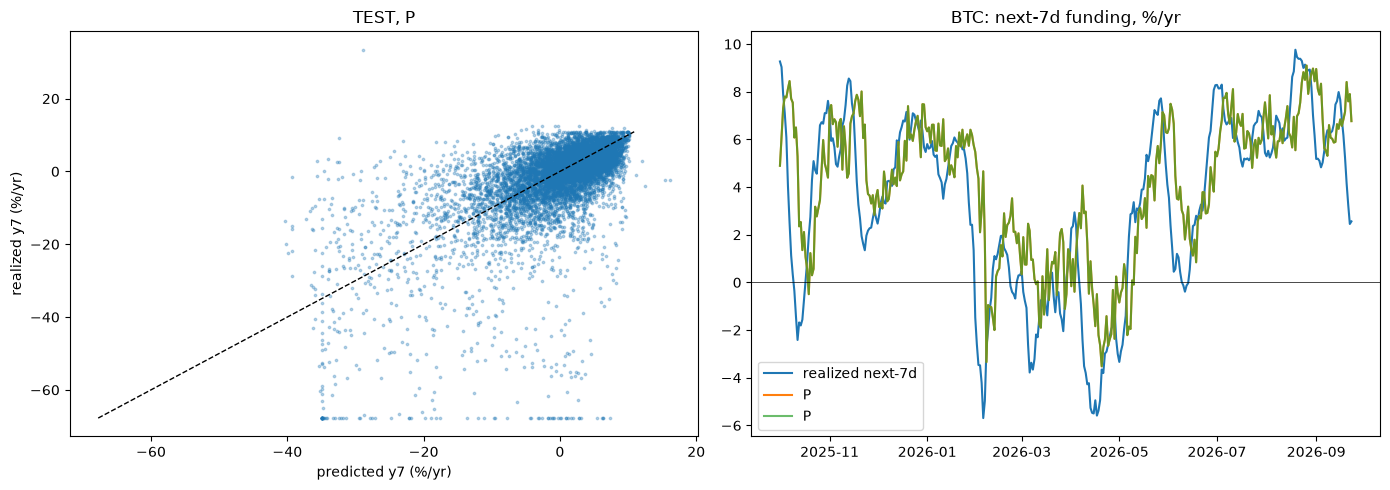

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(100 * te[f'pred_{best}'], 100 * te['y_w'], s=3, alpha=.3); lim = [100 * te.y_w.quantile(.005), 100 * te.y_w.quantile(.995)]
ax[0].plot(lim, lim, 'k--', lw=1); ax[0].set_xlabel('predicted y7 (%/yr)'); ax[0].set_ylabel('realized y7 (%/yr)'); ax[0].set_title(f'TEST, {best}')
a0 = 'BTC' if 'BTC' in te.asset.unique() else te.asset.iloc[0]; g = te[te.asset == a0]
ax[1].plot(g.b, 100 * g.y_w, label='realized next-7d'); ax[1].plot(g.b, 100 * g[f'pred_{best}'], label=best); ax[1].plot(g.b, 100 * g.pred_P, label='P', alpha=.7)
ax[1].axhline(0, c='k', lw=.5); ax[1].legend(); ax[1].set_title(f'{a0}: next-7d funding, %/yr')
plt.tight_layout(); plt.savefig(OUT / '02_pred_vs_real.png', dpi=110); plt.show()